# Semi-supervised OCT classification: ITS and ITS+

Dataset: NEH_UT_2021 (Noor Eye Hospital), classes NORMAL / DRUSEN / CNV.

- **Supervised**: EfficientNet-B0 trained on the labelled scans only.
- **ITS (Paper 1)**: iterative teacher-student pseudo-labelling as published by Alizadeh et al.
- **ITS+ (ours)**: the same loop with a two-head network, class-adaptive full / partial / reject admission, a neighbouring-scan agreement check, strong augmentation with a ramped pseudo-label loss, and a final fine-tune (taken from Papers 2 and 3).

Every cell below was executed; the outputs are stored in this file.

## 1. Live check: load the saved models and classify the test set

In [1]:
%run demo.py --fraction 0.10 --seed 0


NEH_UT_2021 OCT, 3 classes ['NORMAL', 'DRUSEN', 'CNV'], device cuda
labelled scans 940 (10% of training cases), unlabelled scans 8933, test scans 4326 (never used in training)

model                         accuracy  macro-F1  macro-AUC  under-grading
--------------------------------------------------------------------------


Supervised (labelled only)      0.8104    0.7918     0.9074         0.2932


ITS (Paper 1)                   0.8197    0.8000     0.9299         0.3042


ITS+ (ours)                     0.8860    0.8834     0.9581         0.1492

Confusion matrix of ITS+ (ours) (rows = true class, columns = predicted)
             NORMAL   DRUSEN      CNV   recall
    NORMAL     2142       85       15    0.955
    DRUSEN      295     1020       36    0.755
       CNV       16       46      671    0.915

Ten test scans classified by ITS+ (ours):
  NORMAL/68/024_Normal.tif     true NORMAL  predicted NORMAL  confidence 1.00  correct
  NORMAL/61/OD/025_Normal.tif  true NORMAL  predicted NORMAL  confidence 1.00  correct
  DRUSEN/138/013_Drusen.tif    true DRUSEN  predicted NORMAL  confidence 1.00  WRONG
  DRUSEN/93/OS/028_Drusen.tif  true DRUSEN  predicted NORMAL  confidence 1.00  WRONG
  CNV/141/011_CNV.tif          true CNV     predicted CNV     confidence 1.00  correct
  CNV/17/028_Drusen.tif        true DRUSEN  predicted DRUSEN  confidence 1.00  correct
  CNV/10/OD/015_Drusen.tif     true DRUSEN  predicted DRUSEN  confidence 1.00  correct
  CNV/158/023_D

## 2. All test results

In [2]:
import pandas as pd
pd.set_option('display.width', 200)
res = pd.read_csv('outputs/results.csv')
cols = ['label', 'fraction', 'seed', 'best_round', 'accuracy', 'macro_f1', 'macro_auc', 'under_grading_rate']
res[cols].round(4)

,label,fraction,seed,best_round,accuracy,macro_f1,macro_auc,under_grading_rate
0,Supervised,0.1,0,0,0.8104,0.7918,0.9074,0.2932
1,Supervised,0.1,1,0,0.8063,0.8050,0.9190,0.1862
2,Supervised,0.1,2,0,0.8026,0.7824,0.9124,0.2390
3,Supervised (two-head),0.1,0,0,0.8211,0.8197,0.9293,0.1526
4,Supervised (two-head),0.1,1,0,0.8123,0.8040,0.9291,0.1324
5,Supervised (two-head),0.1,2,0,0.8148,0.7968,0.9077,0.2298
6,ITS (Paper 1),0.1,0,1,0.8197,0.8000,0.9299,0.3042
7,ITS (Paper 1),0.1,1,2,0.8234,0.8318,0.9407,0.0974
8,ITS (Paper 1),0.1,2,4,0.8215,0.7992,0.9353,0.2236
9,ITS+ A: two-head,0.1,0,1,0.8546,0.8477,0.9460,0.1915


## 3. Figures

08_comparison.png


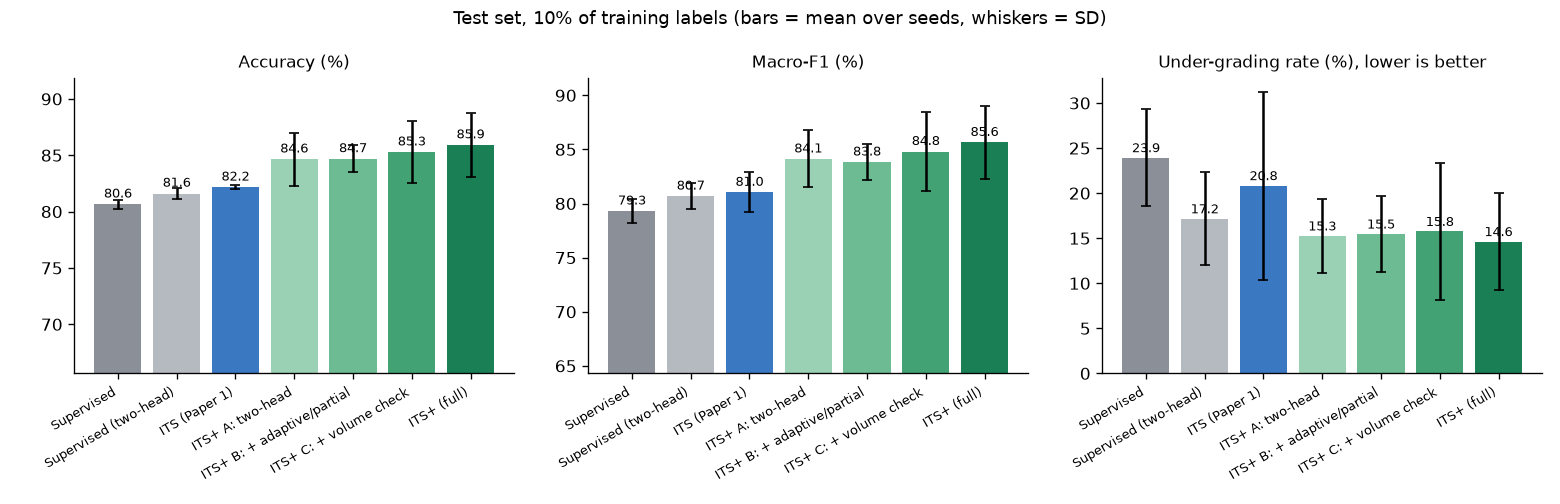

08_confusions.png


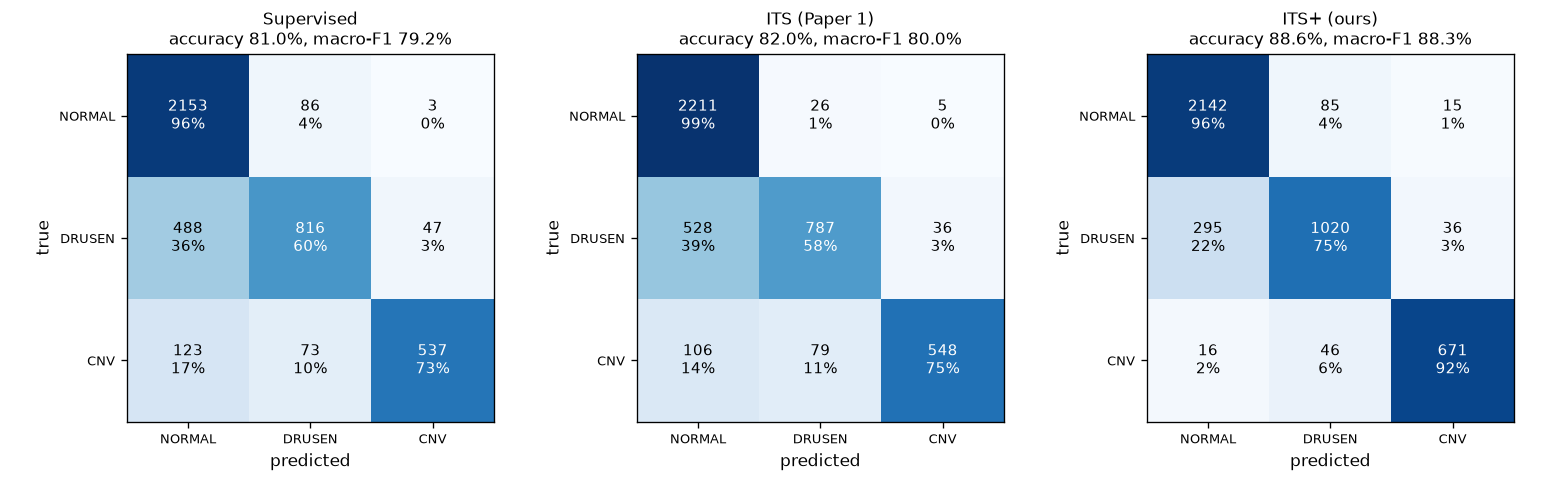

08_rounds.png


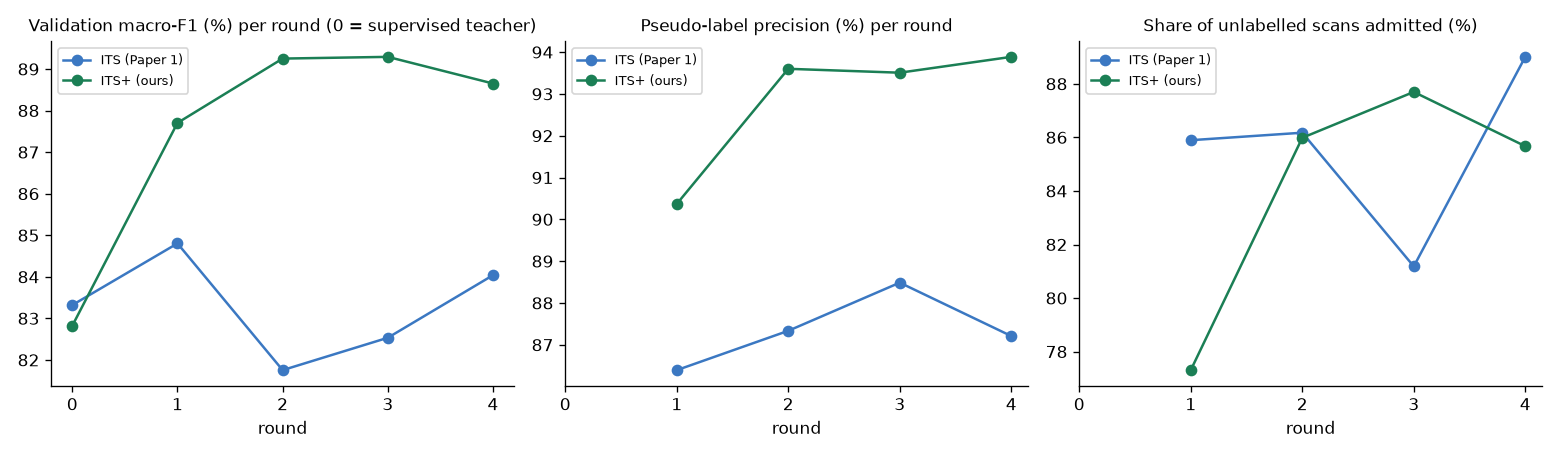

03_augmentations.png


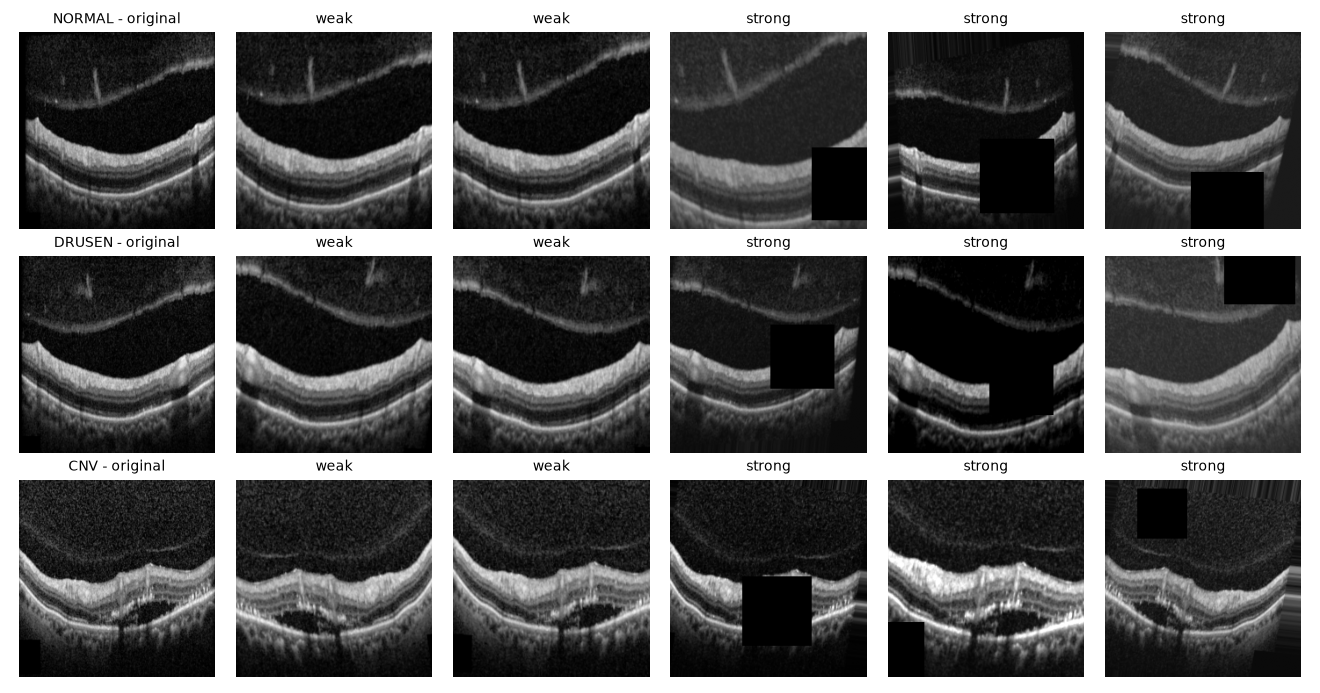

In [3]:
from IPython.display import Image, display
for name in ['08_comparison.png', '08_confusions.png', '08_rounds.png', '03_augmentations.png']:
    print(name)
    display(Image(filename=f'outputs/{name}'))

## 4. Teacher-student rounds (seed 0, 10% labels)

Pseudo-label precision is measured against the hidden true labels for analysis only.

In [4]:
cols = ['round', 'tau', 'kept', 'val_macro_f1', 'val_accuracy', 'admitted', 'coverage', 'full_precision', 'n_PARTIAL', 'precision_PARTIAL']
for run in ['its_f010_s0', 'its_plus_f010_s0']:
    print(run)
    display(pd.read_csv(f'outputs/runs/{run}/rounds.csv').reindex(columns=cols).round(4))

its_f010_s0


,round,tau,kept,val_macro_f1,val_accuracy,admitted,coverage,full_precision,n_PARTIAL,precision_PARTIAL
0,0,NaN,NaN,0.8332,0.8376,NaN,NaN,NaN,NaN,NaN
1,1,0.95,True,0.8480,0.8518,7673.0,0.8589,0.8639,0.0,NaN
2,1,0.99,False,0.8423,0.8331,6890.0,0.7713,0.8827,0.0,NaN
3,2,0.95,True,0.8175,0.8272,7698.0,0.8617,0.8733,0.0,NaN
4,3,0.95,True,0.8253,0.8322,7252.0,0.8118,0.8849,0.0,NaN
5,4,0.95,True,0.8404,0.8443,7951.0,0.8901,0.8721,0.0,NaN


its_plus_f010_s0


,round,tau,kept,val_macro_f1,val_accuracy,admitted,coverage,full_precision,n_PARTIAL,precision_PARTIAL
0,0,NaN,NaN,0.8282,0.8243,NaN,NaN,NaN,NaN,NaN
1,1,class-adaptive 0.980/0.973/0.958,True,0.8770,0.8765,6906.0,0.7731,0.9037,438.0,0.8904
2,2,class-adaptive 0.980/0.956/0.962,True,0.8925,0.8890,7681.0,0.8598,0.9360,228.0,0.9605
3,3,class-adaptive 0.980/0.963/0.966,True,0.8929,0.8894,7834.0,0.8770,0.9351,149.0,0.9866
4,4,class-adaptive 0.980/0.955/0.964,True,0.8865,0.8848,7653.0,0.8567,0.9389,228.0,0.9868
5,fine-tune,NaN,False,0.8862,0.8819,NaN,NaN,NaN,NaN,NaN


## 5. Training log of ITS+ (last 40 lines)

In [5]:
print(''.join(open('outputs/runs/its_plus_f010_s0/log.txt').readlines()[-40:]))

    epoch  8  loss 0.1542  val acc 0.8781  val macro-F1 0.8836    lr 1e-03  70s
    epoch  9  loss 0.1485  val acc 0.8827  val macro-F1 0.8831    lr 1e-03  69s
    epoch 10  loss 0.1273  val acc 0.8731  val macro-F1 0.8701    lr 1e-04  69s
    epoch 11  loss 0.0778  val acc 0.8710  val macro-F1 0.8687    lr 1e-04  69s
    epoch 12  loss 0.0608  val acc 0.8781  val macro-F1 0.8782    lr 1e-04  69s
    epoch 13  loss 0.0551  val acc 0.8836  val macro-F1 0.8847    lr 1e-04  69s
    early stop (no improvement for 8 epochs)
  student val macro-F1 0.8929  val accuracy 0.8894

round 4  threshold class-adaptive 0.980/0.955/0.964: admitted 7653 of 8933 (85.7%), partial 228, full-label precision 0.9389
  per class (count, precision): NORMAL 4201 / 0.923, DRUSEN 1753 / 0.932, CNV 1471 / 0.992
    epoch  1  loss 0.3324  val acc 0.6949  val macro-F1 0.7189 *  lr 1e-03  68s
    epoch  2  loss 0.1520  val acc 0.7759  val macro-F1 0.7709 *  lr 1e-03  68s
    epoch  3  loss 0.1119  val acc 0.8239  val 